In [1]:
import pandas as pd
import numpy as np

In [3]:
file_path="../Data/Raw/CreditGuard_Dataset.xlsx"
df = pd.read_excel(file_path)
df.shape

(500, 19)

In [4]:
data = df.copy()
print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:",data.shape)

Original Dataset Shape: (500, 19)
Working Dataset Shape: (500, 19)


In [5]:
missing_summary = pd.DataFrame({
    "Missing Values" : data.isnull().sum(),
    "Missing Percentage" : (data.isnull().mean()*100).round(2)
})
missing_summary=missing_summary[missing_summary["Missing Values"]>0]
missing_summary


,Missing Values,Missing Percentage
Income,39,7.8
Credit_Score,2,0.4
Loan_Balance,29,5.8


In [7]:
import matplotlib.pyplot as plt

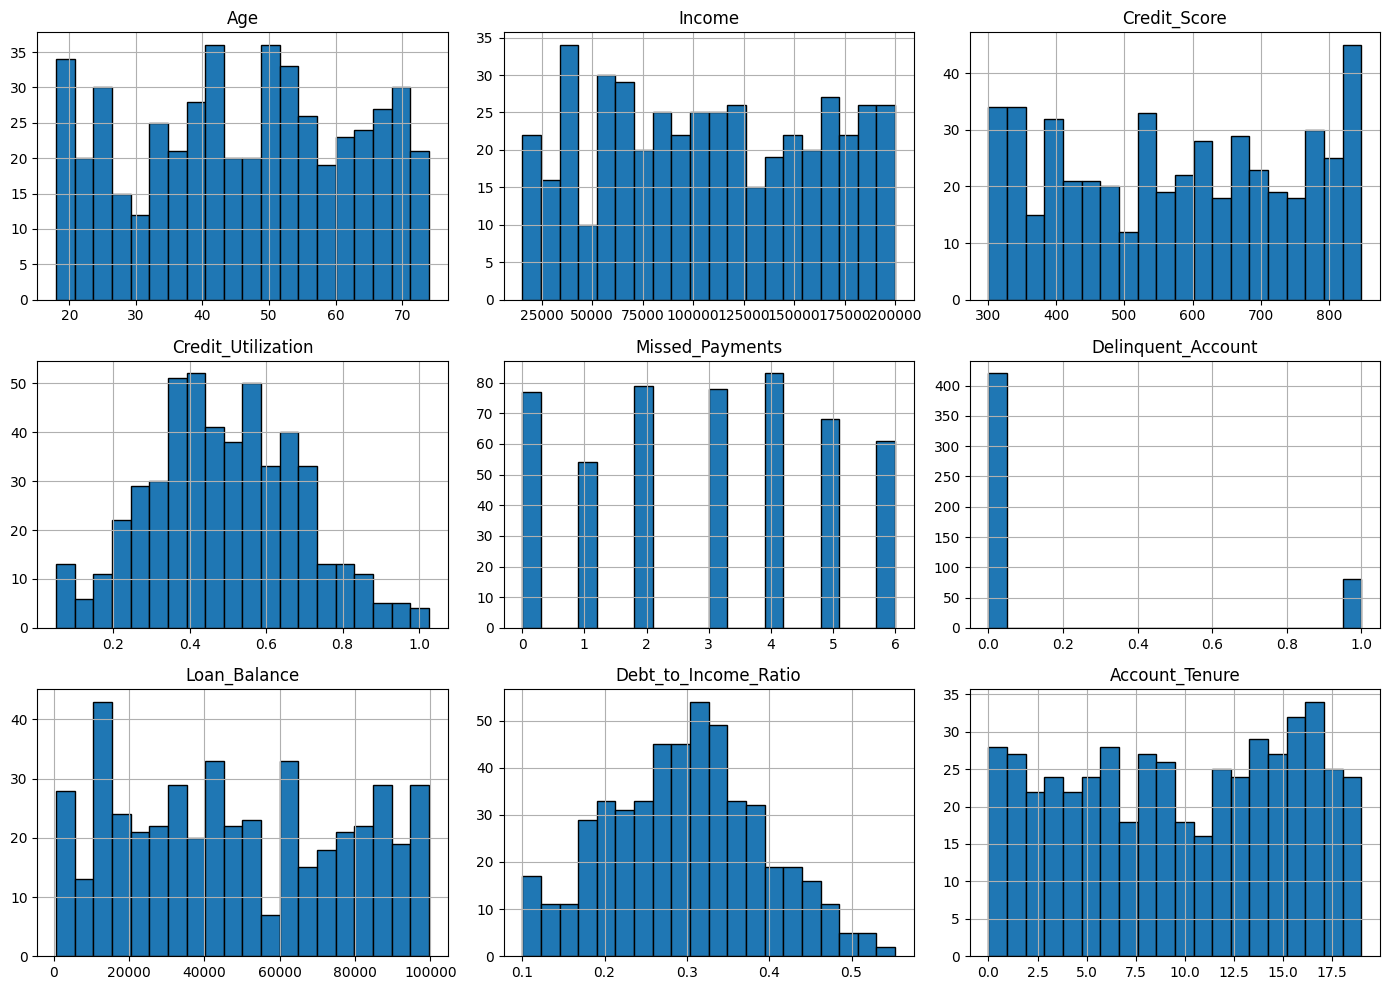

In [8]:
numerical_columns = data.select_dtypes(include=np.number).columns
data[numerical_columns].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.tight_layout()
plt.show()

In [9]:
for column in data.columns:
    if data[column].isnull().sum() > 0:
        print(f"\n{column}")
        print("Missing:", data[column].isnull().sum())
        print("Median:", data[column].median())
        print("Mean:", data[column].mean())
        print("Skewness:", data[column].skew())


Income
Missing: 39
Median: 107658.0
Mean: 108379.89370932755
Skewness: 0.04608650905666607

Credit_Score
Missing: 2
Median: 586.0
Mean: 577.7168674698795
Skewness: -0.03405560813524967

Loan_Balance
Missing: 29
Median: 45776.0
Mean: 48654.42887473461
Skewness: 0.10519664223226481


In [10]:
print("Employment Status — Before Cleaning")
print(data["Employment_Status"].value_counts(dropna=False))

Employment Status — Before Cleaning
Employment_Status
Unemployed       93
retired          87
Employed         82
EMP              81
Self-employed    80
employed         77
Name: count, dtype: int64


In [11]:
data["Employment_Status"] = (
    data["Employment_Status"]
    .str.strip()
    .str.lower()
)
print("Employment Status — After Formatting")
print(data["Employment_Status"].value_counts(dropna=False))

Employment Status — After Formatting
Employment_Status
employed         159
unemployed        93
retired           87
emp               81
self-employed     80
Name: count, dtype: int64


In [12]:
payment_columns = [f"Month_{i}" for i in range(1, 7)]
for column in payment_columns:
    print(f"\n{column}")
    print(data[column].value_counts(dropna=False))


Month_1
Month_1
On-time    177
Missed     164
Late       159
Name: count, dtype: int64

Month_2
Month_2
Late       173
Missed     167
On-time    160
Name: count, dtype: int64

Month_3
Month_3
Late       169
On-time    169
Missed     162
Name: count, dtype: int64

Month_4
Month_4
Late       181
Missed     160
On-time    159
Name: count, dtype: int64

Month_5
Month_5
Missed     187
On-time    162
Late       151
Name: count, dtype: int64

Month_6
Month_6
Late       172
Missed     168
On-time    160
Name: count, dtype: int64


In [13]:
for column in payment_columns:
    data[column] = (
        data[column]
        .astype("string")
        .str.strip()
        .str.lower()
    )

In [14]:
payment_mapping = {
    "on-time": 0,
    "late": 1,
    "missed": 2
}
for column in payment_columns:
    data[column] = data[column].map(payment_mapping)
print(data[payment_columns].head())

   Month_1  Month_2  Month_3  Month_4  Month_5  Month_6
0        1        1        2        1        2        1
1        2        2        1        2        0        0
2        2        1        1        0        2        1
3        1        2        1        2        1        1
4        2        0        2        1        1        1


In [15]:
categorical_columns = data.select_dtypes(
    include=["object", "string"]
).columns

for column in categorical_columns:
    print(f"\n{column}")
    print(data[column].value_counts(dropna=False))


Customer_ID
Customer_ID
CUST0001    1
CUST0002    1
CUST0003    1
CUST0004    1
CUST0005    1
           ..
CUST0496    1
CUST0497    1
CUST0498    1
CUST0499    1
CUST0500    1
Name: count, Length: 500, dtype: int64

Employment_Status
Employment_Status
employed         159
unemployed        93
retired           87
emp               81
self-employed     80
Name: count, dtype: int64

Credit_Card_Type
Credit_Card_Type
Gold        118
Student     112
Business    108
Standard     86
Platinum     76
Name: count, dtype: int64

Location
Location
Los Angeles    107
Phoenix        103
Chicago        103
Houston         95
New York        92
Name: count, dtype: int64


In [16]:
for column in payment_columns:
    print(f"\n{column} unique values:")
    print(data[column].unique())


Month_1 unique values:
[1 2 0]

Month_2 unique values:
[1 2 0]

Month_3 unique values:
[2 1 0]

Month_4 unique values:
[1 2 0]

Month_5 unique values:
[2 0 1]

Month_6 unique values:
[1 0 2]


In [17]:
numeric_columns = data.select_dtypes(include=np.number).columns
print(data[numeric_columns].describe().T)

                      count           mean           std       min  \
Age                   500.0      46.266000     16.187629     18.00   
Income                461.0  108379.893709  53662.723741  15404.00   
Credit_Score          498.0     577.716867    168.881211    301.00   
Credit_Utilization    500.0       0.491446      0.197103      0.05   
Missed_Payments       500.0       2.968000      1.946935      0.00   
Delinquent_Account    500.0       0.160000      0.366973      0.00   
Loan_Balance          471.0   48654.428875  29395.537273    612.00   
Debt_to_Income_Ratio  500.0       0.298862      0.094521      0.10   
Account_Tenure        500.0       9.740000      5.923054      0.00   
Month_1               500.0       0.974000      0.826250      0.00   
Month_2               500.0       1.014000      0.809391      0.00   
Month_3               500.0       0.986000      0.814328      0.00   
Month_4               500.0       1.002000      0.799546      0.00   
Month_5             

In [18]:
print("Negative Income:", (data["Income"] < 0).sum())
print("Negative Loan Balance:", (data["Loan_Balance"] < 0).sum())

print("Credit Utilization below 0:",
      (data["Credit_Utilization"] < 0).sum())

print("Credit Utilization above 1:",
      (data["Credit_Utilization"] > 1).sum())

print("Credit Score outside 300–850:",
      ((data["Credit_Score"] < 300) |
       (data["Credit_Score"] > 850)).sum())

Negative Income: 0
Negative Loan Balance: 0
Credit Utilization below 0: 0
Credit Utilization above 1: 4
Credit Score outside 300–850: 0


In [19]:
print("Original dataset shape:", df.shape)
print("Preprocessed working dataset shape:", data.shape)

Original dataset shape: (500, 19)
Preprocessed working dataset shape: (500, 19)


In [20]:
print("Missing values after current preprocessing:")

print(
    data.isnull().sum()[data.isnull().sum() > 0]
)

Missing values after current preprocessing:
Income          39
Credit_Score     2
Loan_Balance    29
dtype: int64


In [21]:
import os
os.makedirs("../data/interim", exist_ok=True)
data.to_csv(
    "../data/interim/creditguard_preprocessing_checkpoint.csv",
    index=False
)
print("Preprocessing checkpoint saved successfully!")

Preprocessing checkpoint saved successfully!


In [22]:
print("Original dataset shape:", df.shape)
print("Working dataset shape:", data.shape)
print("\nColumns:")
print(data.columns.tolist())

Original dataset shape: (500, 19)
Working dataset shape: (500, 19)

Columns:
['Customer_ID', 'Age', 'Income', 'Credit_Score', 'Credit_Utilization', 'Missed_Payments', 'Delinquent_Account', 'Loan_Balance', 'Debt_to_Income_Ratio', 'Employment_Status', 'Account_Tenure', 'Credit_Card_Type', 'Location', 'Month_1', 'Month_2', 'Month_3', 'Month_4', 'Month_5', 'Month_6']


In [23]:
print(data.dtypes)

Customer_ID                 str
Age                       int64
Income                  float64
Credit_Score            float64
Credit_Utilization      float64
Missed_Payments           int64
Delinquent_Account        int64
Loan_Balance            float64
Debt_to_Income_Ratio    float64
Employment_Status           str
Account_Tenure            int64
Credit_Card_Type            str
Location                    str
Month_1                   int64
Month_2                   int64
Month_3                   int64
Month_4                   int64
Month_5                   int64
Month_6                   int64
dtype: object


In [24]:
print("Duplicate rows:", data.duplicated().sum())
print(
    "Duplicate Customer IDs:",
    data["Customer_ID"].duplicated().sum()
)

Duplicate rows: 0
Duplicate Customer IDs: 0


In [25]:
print(data["Delinquent_Account"].value_counts(dropna=False))
print("\nTarget percentages:")
print(
    data["Delinquent_Account"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Delinquent_Account
0    420
1     80
Name: count, dtype: int64

Target percentages:
Delinquent_Account
0    84.0
1    16.0
Name: proportion, dtype: float64


In [26]:
print(
    "Missing target values:",
    data["Delinquent_Account"].isnull().sum()
)

print(
    "Unexpected target values:",
    data.loc[
        ~data["Delinquent_Account"].isin([0, 1]),
        "Delinquent_Account"
    ].unique()
)

Missing target values: 0
Unexpected target values: []


In [27]:
print("Employment categories:")
print(data["Employment_Status"].value_counts(dropna=False))

Employment categories:
Employment_Status
employed         159
unemployed        93
retired           87
emp               81
self-employed     80
Name: count, dtype: int64


In [28]:
employment_comparison = pd.DataFrame({
    "Original": df["Employment_Status"].value_counts(),
    "Cleaned": data["Employment_Status"].value_counts()
})

employment_comparison

,Original,Cleaned
Employment_Status,,
EMP,81.0,NaN
Employed,82.0,NaN
Self-employed,80.0,NaN
Unemployed,93.0,NaN
emp,NaN,81.0
employed,77.0,159.0
retired,87.0,87.0
self-employed,NaN,80.0
unemployed,NaN,93.0


In [29]:
payment_mapping = {
    "on-time": 0,
    "late": 1,
    "missed": 2
}

for column in payment_columns:

    original_values = (
        df[column]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    expected_values = original_values.map(payment_mapping)

    matches = (
        expected_values.fillna(-999)
        == data[column].fillna(-999)
    )

    print(
        column,
        "Encoding correct:",
        matches.all()
    )

Month_1 Encoding correct: True
Month_2 Encoding correct: True
Month_3 Encoding correct: True
Month_4 Encoding correct: True
Month_5 Encoding correct: True
Month_6 Encoding correct: True


In [30]:
for column in payment_columns:
    print(f"\n{column}")
    print("Unique encoded values:")
    print(data[column].unique())
    print("Missing values:", data[column].isnull().sum())


Month_1
Unique encoded values:
[1 2 0]
Missing values: 0

Month_2
Unique encoded values:
[1 2 0]
Missing values: 0

Month_3
Unique encoded values:
[2 1 0]
Missing values: 0

Month_4
Unique encoded values:
[1 2 0]
Missing values: 0

Month_5
Unique encoded values:
[2 0 1]
Missing values: 0

Month_6
Unique encoded values:
[1 0 2]
Missing values: 0


In [31]:
print(data["Credit_Utilization"].describe())

print(
    "\nValues above 1:",
    data.loc[
        data["Credit_Utilization"] > 1,
        "Credit_Utilization"
    ]
)

count    500.000000
mean       0.491446
std        0.197103
min        0.050000
25%        0.356486
50%        0.485636
75%        0.634440
max        1.025843
Name: Credit_Utilization, dtype: float64

Values above 1: 89     1.025843
265    1.025017
292    1.002482
426    1.008734
Name: Credit_Utilization, dtype: float64


In [32]:
numerical_columns = [
    "Age",
    "Income",
    "Credit_Score",
    "Credit_Utilization",
    "Missed_Payments",
    "Loan_Balance",
    "Debt_to_Income_Ratio",
    "Account_Tenure"
]

for column in numerical_columns:

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    print(f"\n{column}")
    print("Potential outliers:", len(outliers))
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))


Age
Potential outliers: 0
Lower bound: -6.38
Upper bound: 98.62

Income
Potential outliers: 0
Lower bound: -77863.5
Upper bound: 295892.5

Credit_Score
Potential outliers: 0
Lower bound: -45.25
Upper bound: 1190.75

Credit_Utilization
Potential outliers: 0
Lower bound: -0.06
Upper bound: 1.05

Missed_Payments
Potential outliers: 0
Lower bound: -5.0
Upper bound: 11.0

Loan_Balance
Potential outliers: 0
Lower bound: -54028.5
Upper bound: 153291.5

Debt_to_Income_Ratio
Potential outliers: 0
Lower bound: 0.04
Upper bound: 0.56

Account_Tenure
Potential outliers: 0
Lower bound: -10.0
Upper bound: 30.0


In [33]:
missing_report = pd.DataFrame({
    "Missing Count": data.isnull().sum(),
    "Missing Percentage": (
        data.isnull().mean() * 100
    ).round(2)
})

missing_report = missing_report[
    missing_report["Missing Count"] > 0
]

missing_report

,Missing Count,Missing Percentage
Income,39,7.8
Credit_Score,2,0.4
Loan_Balance,29,5.8


In [34]:
print("Negative income:",
      (data["Income"] < 0).sum())

print("Negative loan balance:",
      (data["Loan_Balance"] < 0).sum())

print("Invalid age:",
      (data["Age"] < 18).sum())

print("Invalid credit scores:",
      ((data["Credit_Score"] < 300) |
       (data["Credit_Score"] > 850)).sum())

Negative income: 0
Negative loan balance: 0
Invalid age: 0
Invalid credit scores: 0


In [35]:
for column in payment_columns:

    invalid_values = data[
        ~data[column].isin([0, 1, 2]) &
        data[column].notna()
    ]

    print(
        column,
        "Invalid encoded values:",
        len(invalid_values)
    )

Month_1 Invalid encoded values: 0
Month_2 Invalid encoded values: 0
Month_3 Invalid encoded values: 0
Month_4 Invalid encoded values: 0
Month_5 Invalid encoded values: 0
Month_6 Invalid encoded values: 0


In [36]:
import os

os.makedirs("../data/interim", exist_ok=True)

data.to_csv(
    "../data/interim/creditguard_validated.csv",
    index=False
)

print("Validated dataset saved successfully!")
print("Final shape:", data.shape)

Validated dataset saved successfully!
Final shape: (500, 19)
